In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import os, glob
from scipy.sparse import csr_matrix, coo_matrix
from collections import defaultdict 
import matplotlib.pyplot as plt 
import json 
# import harmonypy as hm
import umap
from scipy.sparse import vstack


## 人的数据整合

In [2]:
mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()
new_var = [ele.upper() for ele in mdata.var.index]
mdata.var.index = new_var

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()

## ref data 
adata = sc.read_h5ad('../supp_species/dog_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## new obs  
species = list(scdata.obs.species.values) + ['dog']*adata.n_obs 
sly_anno = list(scdata.obs.sly_anno.values) + ['undefine']*adata.n_obs 

X1 = scdata.X 
X2 = adata.X 
# X = vstack([X1, X2]).tocsr() 

# ## new data 
# scdata = ad.AnnData(X)
# scdata.obs.loc[:,'species'] = species 
# scdata.obs.loc[:,'sly_anno'] = sly_anno  

# sc.pp.highly_variable_genes(scdata , n_top_genes= 3000)
# scdata = scdata[:,scdata.var.highly_variable]
# sc.tl.pca(scdata)
# print('PCA OVER')


(21723, 9911) (21723, 9911)
mutual gene number 8819


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [3]:
import ot
from scipy.spatial.distance import cdist

# --- Step 1: 转 dense（CSR → ndarray）---
X1_dense = X1.toarray() if hasattr(X1, 'toarray') else X1  
X2_dense = X2.toarray() if hasattr(X2, 'toarray') else X2

# --- Step 2: Cost matrix（基因表达空间的 pairwise 欧氏距离）---
C = cdist(X2_dense, X1_dense, metric='euclidean')
C = C / C.max()                            # 归一化，稳定 Sinkhorn

# --- Step 3: 熵正则化 OT（Sinkhorn）---
n_query, n_ref = X2_dense.shape[0], X1_dense.shape[0]
a = np.ones(n_query) / n_query             # 查询侧（dog）均匀分布
b = np.ones(n_ref)   / n_ref               # 参考侧（其余物种）均匀分布
epsilon = 5e-3                             # 正则强度，越小越接近精确 OT
P = ot.sinkhorn(a, b, C, epsilon)          # P: (n_query × n_ref) 概率转移矩阵

# --- Step 4: 行归一化（数值安全兜底）---
P = P / P.sum(axis=1, keepdims=True)       # 每行和 = 1

# --- Step 5: Barycentric 投影，把 scdata 的 UMAP 坐标搬运给 adata ---
adata.obsm['X_umap'] = P @ scdata.obsm['X_umap']

/tmp/ipykernel_734987/4075039854.py:23: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  adata.obsm['X_umap'] = P @ scdata.obsm['X_umap']


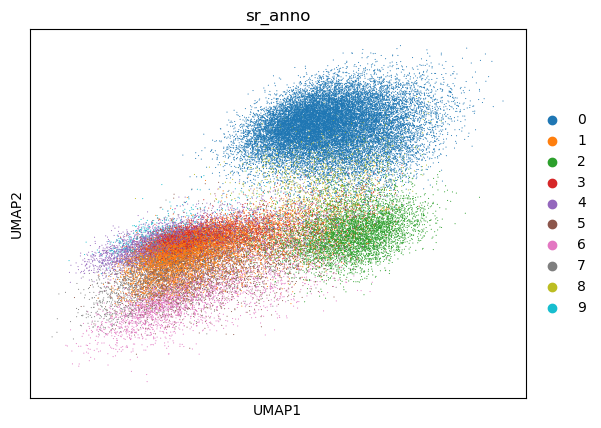

In [5]:
sc.pl.umap(adata , color = 'sr_anno')

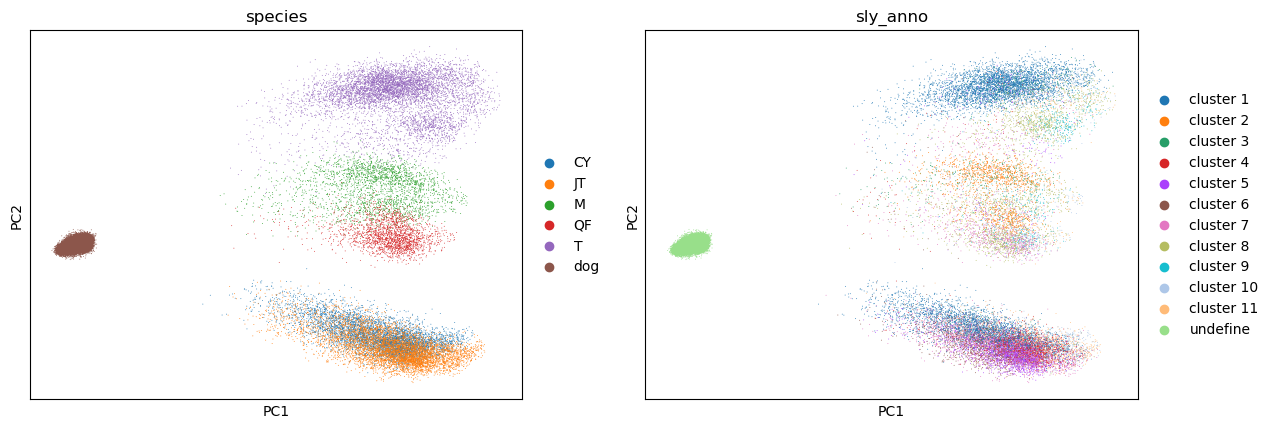

In [29]:
sc.pl.pca(scdata, color = ['species', 'sly_anno'])

(50933, 51) (21723, 51)


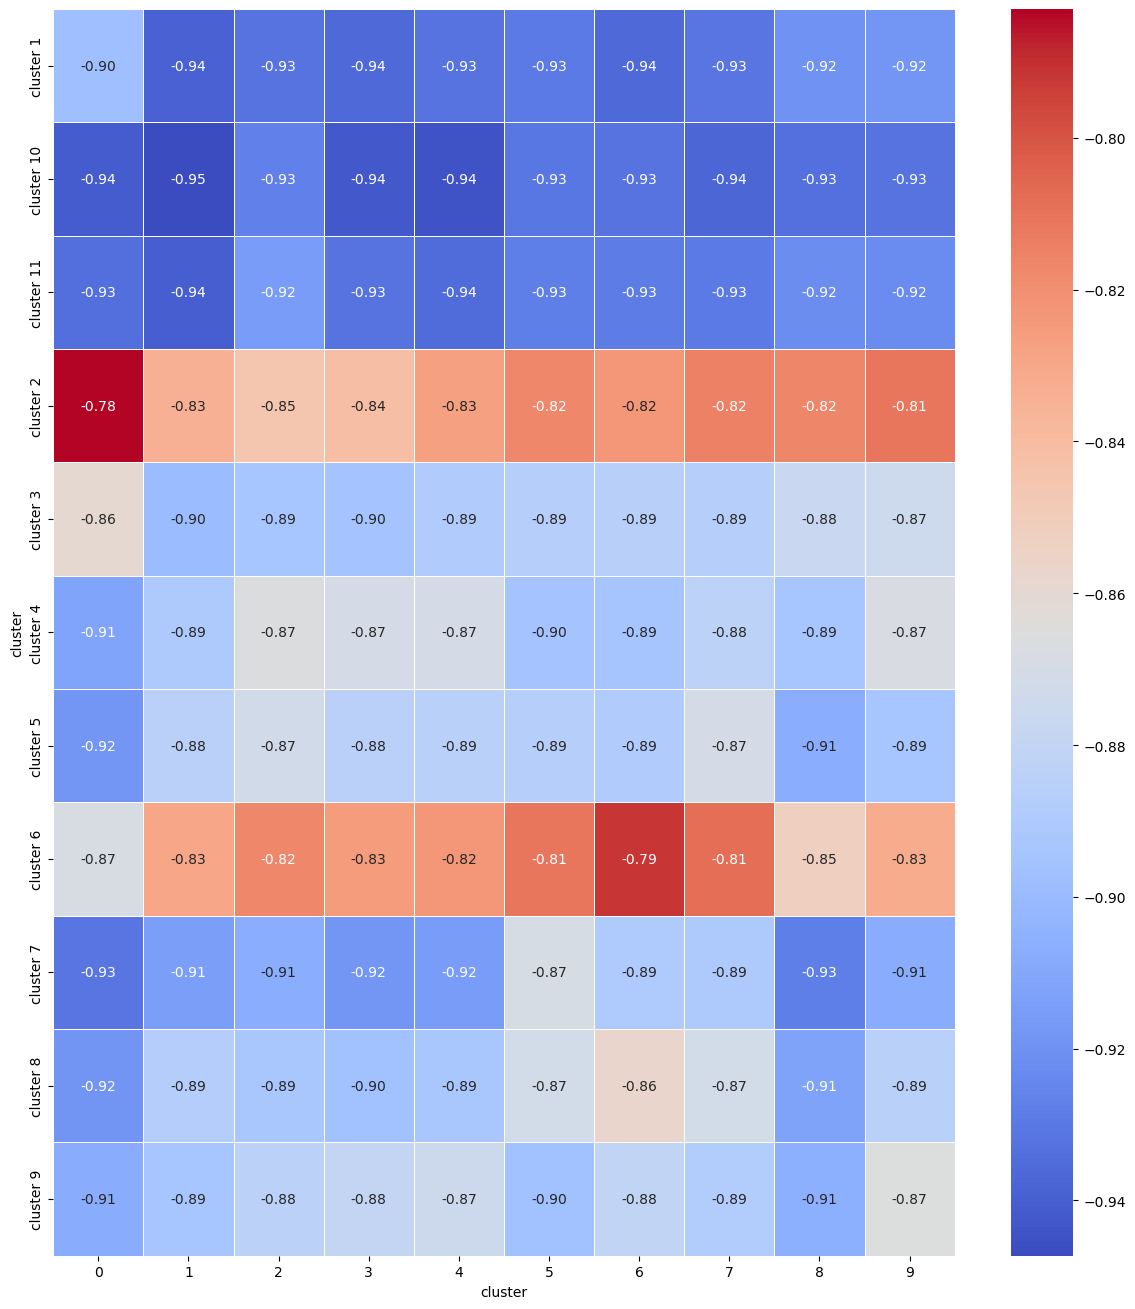

In [28]:
X_query = scdata.obsm['X_pca'][scdata.obs.species == 'dog',:]
X_ref = scdata.obsm['X_pca'][scdata.obs.species != 'dog', :]

df_query = pd.DataFrame(X_query)
df_ref = pd.DataFrame(X_ref)
df_query.loc[:,'cluster'] = adata.obs.sr_anno.values.astype(object)
df_ref.loc[:,'cluster'] = scdata.obs.loc[scdata.obs.species != 'dog', 'sly_anno'].values.astype(object) 
print(df_query.shape, df_ref.shape)

# 按 cluster 组内求均值（centroid in PCA space）
cluster_query = df_query.groupby('cluster').mean()
cluster_ref  = df_ref.groupby('cluster').mean()

# 两两 cosine similarity
from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(cluster_ref.values, cluster_query.values)
sim_df = pd.DataFrame(sim, index=cluster_ref.index, columns=cluster_query.index)

# heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(max(6, len(cluster_query) * 1.2), max(6, len(cluster_ref) * 1.2)))
sns.heatmap(sim_df, annot=True, cmap='coolwarm',  fmt='.2f', linewidths=.5)
plt.tight_layout()
plt.show()

/home/rsun@ZHANGroup.local/anaconda3/envs/scpair/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


PCA OVER
KNN over


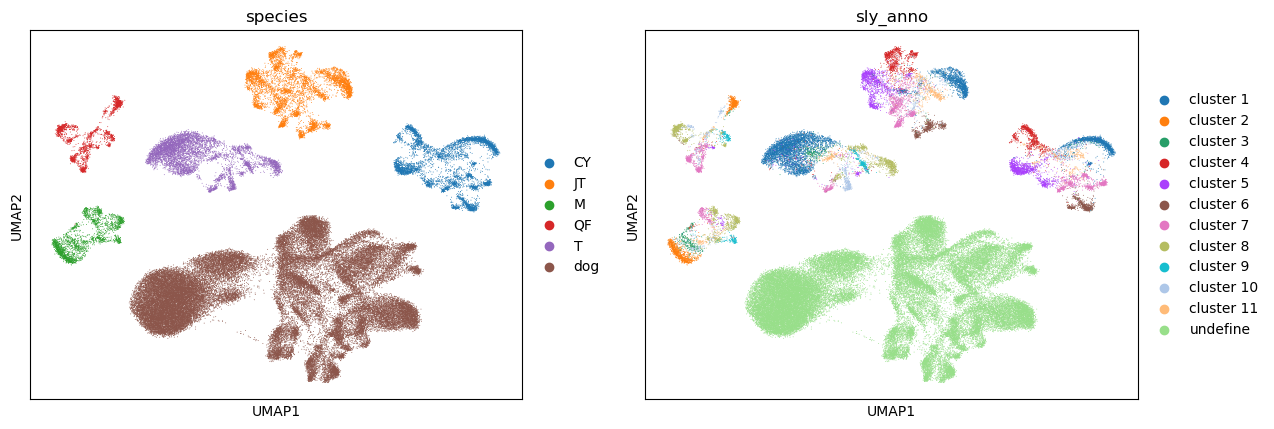

In [13]:
sc.pp.highly_variable_genes(scdata , n_top_genes= 3000)
scdata = scdata[:,scdata.var.highly_variable]
sc.tl.pca(scdata)
print('PCA OVER')
sc.pp.neighbors(scdata,)
print('KNN over')
sc.tl.umap(scdata, min_dist = 0.5)
sc.pl.umap(scdata, color = ['species', 'sly_anno'])

2026-07-18 15:00:50,953 - harmonypy - INFO - Running Harmony
2026-07-18 15:00:50,954 - harmonypy - INFO -   Parameters:
2026-07-18 15:00:50,955 - harmonypy - INFO -     max_iter_harmony: 100
2026-07-18 15:00:50,956 - harmonypy - INFO -     max_iter_kmeans: 4
2026-07-18 15:00:50,956 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-07-18 15:00:50,956 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-07-18 15:00:50,957 - harmonypy - INFO -     nclust: 100


2026-07-18 15:00:50,957 - harmonypy - INFO -     block_size: 0.05
2026-07-18 15:00:50,958 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-07-18 15:00:50,959 - harmonypy - INFO -     theta: [100. 100. 100. 100. 100. 100.]
2026-07-18 15:00:50,959 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-07-18 15:00:50,960 - harmonypy - INFO -     verbose: True
2026-07-18 15:00:50,960 - harmonypy - INFO -     random_state: 0
2026-07-18 15:00:50,960 - harmonypy - INFO -   Data: 50 PCs × 72656 cells
2026-07-18 15:00:50,962 - harmonypy - INFO -   Batch variables: ['species']
2026-07-18 15:00:51,005 - harmonypy - INFO - Computing initial centroids...
2026-07-18 15:00:53,222 - harmonypy - INFO - Initialization complete.
2026-07-18 15:00:53,223 - harmonypy - INFO - Iteration 1 of 100
2026-07-18 15:00:54,781 - harmonypy - INFO - Iteration 2 of 100
2026-07-18 15:00:56,467 - harmonypy - INFO - Iteration 3 of 100
2026-07-18 15:00:58,137 - harmonypy - INFO - Iteration 4 of 100
2026-07-18

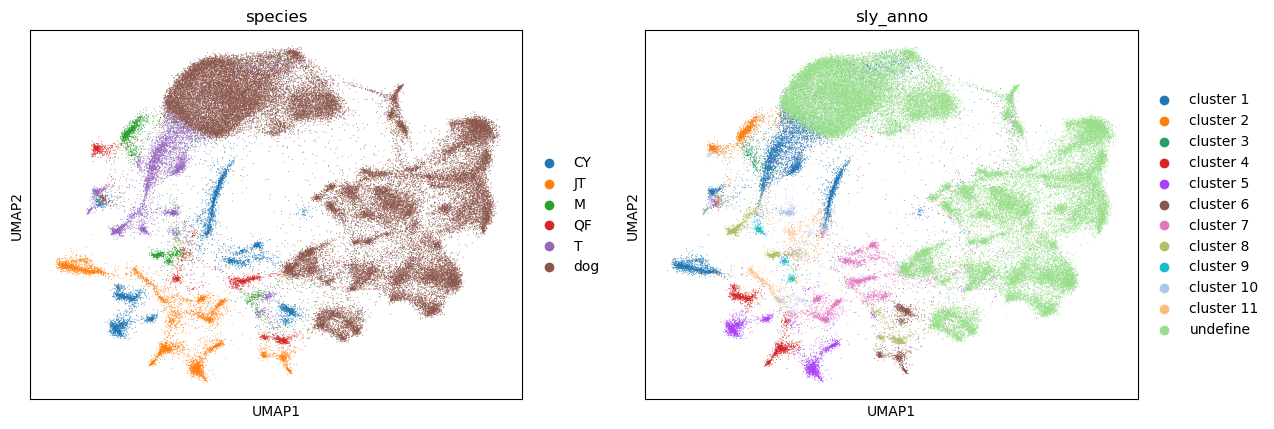

In [19]:
pcs = scdata.obsm['X_pca'] #pd.read_csv("data/pbmc_3500_pcs.tsv.gz", sep="\t")
meta = scdata.obs.copy() #pd.read_csv("data/pbmc_3500_meta.tsv.gz", sep="\t") 

harmony_out = hm.run_harmony(pcs, meta, "species", ncores=1, theta = 100, max_iter_harmony=100)
scdata.obsm['X_pca_harmony'] = harmony_out.Z_corr  


# 1. 降采样 30K cells 拟合 UMAP
np.random.seed(42)
sub_idx = np.random.choice(scdata.n_obs, size=20000, replace=False)
X_sub = scdata[sub_idx].obsm['X_pca_harmony']

umap_model = umap.UMAP(random_state=42, min_dist = 0.25)
umap_model.fit(X_sub)

# 2. 全部细胞 transform 获得最终 UMAP
X_all = scdata.obsm['X_pca_harmony']
scdata.obsm['X_umap_v0'] = scdata.obsm['X_umap'].copy() 
scdata.obsm['X_umap'] = umap_model.transform(X_all)
sc.pl.umap(scdata, color = ['species','sly_anno'])

In [20]:
mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()
new_var = [ele.upper() for ele in mdata.var.index]
mdata.var.index = new_var

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()

## ref data 
adata = sc.read_h5ad('../supp_species/dog_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)



(21723, 9911) (21723, 9911)
mutual gene number 8819


/home/rsun@ZHANGroup.local/anaconda3/envs/scpair/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


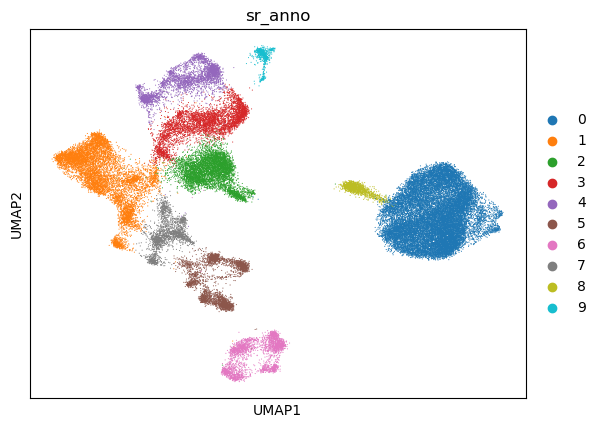

In [21]:
sc.pl.umap(adata, color = 'sr_anno')

## 